# Análise dos dados de um app de delivery

Importanto os pacotes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.stats.proportion as prop
import warnings

In [2]:
warnings.filterwarnings('ignore')

chamando funções

In [3]:
%run ./Funcoes.ipynb

## Carregando os dados

In [4]:
dados =  pd.read_csv(r"C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\dados\dados.csv")

In [5]:
# Visualizar as 5 primeiras linhas da tabela
dados.head()

,ClientId,DataExtracao,Score_Credito,Estado,Gênero,Idade,Tempo_Cliente,Limite_Credito_Mercado,Qte_Categorias,Usa_Cartao_Credito,Programa_Fidelidade,Soma_Pedidos_Acumulados,DataUltimaTransacao,Data_Referencia,Dias_sem_Atividade,Churn
0,345568,2019-06-30,619,São Paulo,Feminino,42,2,0.00,1,1,1,422.29,2019-09-14,2019-10-30,46,1
1,345569,2019-06-30,608,Rio de Janeiro,Feminino,41,1,838.08,1,0,1,468.93,2019-10-05,2019-10-30,25,0
2,345570,2019-06-30,502,São Paulo,Feminino,42,8,1596.61,3,1,0,474.71,2019-08-20,2019-10-30,71,1
3,345571,2019-06-30,699,São Paulo,Feminino,39,1,0.00,2,0,0,390.94,2019-10-21,2019-10-30,9,0
4,345572,2019-06-30,850,Rio de Janeiro,Feminino,43,2,1255.11,1,1,1,329.52,2019-10-26,2019-10-30,4,0


## Verificação de valores ausentes e linhas duplicadas

In [6]:
# Verificação de valores ausentes
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ClientId                 10000 non-null  int64  
 1   DataExtracao             10000 non-null  object 
 2   Score_Credito            10000 non-null  int64  
 3   Estado                   10000 non-null  object 
 4   Gênero                   10000 non-null  object 
 5   Idade                    10000 non-null  int64  
 6   Tempo_Cliente            10000 non-null  int64  
 7   Limite_Credito_Mercado   10000 non-null  float64
 8   Qte_Categorias           10000 non-null  int64  
 9   Usa_Cartao_Credito       10000 non-null  int64  
 10  Programa_Fidelidade      10000 non-null  int64  
 11  Soma_Pedidos_Acumulados  10000 non-null  float64
 12  DataUltimaTransacao      10000 non-null  object 
 13  Data_Referencia          10000 non-null  object 
 14  Dias_sem_Atividade     

In [7]:
# Verificando dados duplicados

dados.duplicated().sum()

0

#### Unicidade dos Ids dos clientes

In [14]:
ids_unicos = dados['ClientId'].unique()

In [15]:
ids_unicos

array([345568, 345569, 345570, ..., 355565, 355566, 355567], dtype=int64)

In [16]:
len(ids_unicos)

10000

## Alterando as colunas com datas para datetime

In [8]:
dados['DataExtracao'] = pd.to_datetime(dados['DataExtracao'])

In [9]:
dados['DataUltimaTransacao'] = pd.to_datetime(dados['DataUltimaTransacao'])

In [10]:
dados['Data_Referencia'] = pd.to_datetime(dados['Data_Referencia'])

In [11]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   ClientId                 10000 non-null  int64         
 1   DataExtracao             10000 non-null  datetime64[ns]
 2   Score_Credito            10000 non-null  int64         
 3   Estado                   10000 non-null  object        
 4   Gênero                   10000 non-null  object        
 5   Idade                    10000 non-null  int64         
 6   Tempo_Cliente            10000 non-null  int64         
 7   Limite_Credito_Mercado   10000 non-null  float64       
 8   Qte_Categorias           10000 non-null  int64         
 9   Usa_Cartao_Credito       10000 non-null  int64         
 10  Programa_Fidelidade      10000 non-null  int64         
 11  Soma_Pedidos_Acumulados  10000 non-null  float64       
 12  DataUltimaTransacao      10000 no

In [12]:
dados.head()

,ClientId,DataExtracao,Score_Credito,Estado,Gênero,Idade,Tempo_Cliente,Limite_Credito_Mercado,Qte_Categorias,Usa_Cartao_Credito,Programa_Fidelidade,Soma_Pedidos_Acumulados,DataUltimaTransacao,Data_Referencia,Dias_sem_Atividade,Churn
0,345568,2019-06-30,619,São Paulo,Feminino,42,2,0.00,1,1,1,422.29,2019-09-14,2019-10-30,46,1
1,345569,2019-06-30,608,Rio de Janeiro,Feminino,41,1,838.08,1,0,1,468.93,2019-10-05,2019-10-30,25,0
2,345570,2019-06-30,502,São Paulo,Feminino,42,8,1596.61,3,1,0,474.71,2019-08-20,2019-10-30,71,1
3,345571,2019-06-30,699,São Paulo,Feminino,39,1,0.00,2,0,0,390.94,2019-10-21,2019-10-30,9,0
4,345572,2019-06-30,850,Rio de Janeiro,Feminino,43,2,1255.11,1,1,1,329.52,2019-10-26,2019-10-30,4,0


In [13]:
# salvando o dataframe
dados.to_csv(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\dados\dados_v1.csv', index=False)

## Análise Exploratórias dos dados (unidimensional)

### Score_Credito

In [14]:
dados["Score_Credito"].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: Score_Credito, dtype: float64

In [15]:
medidas_Score_Credito = pd.DataFrame(dados["Score_Credito"].describe())
medidas_Score_Credito

,Score_Credito
count,10000.000000
mean,650.528800
std,96.653299
min,350.000000
25%,584.000000
50%,652.000000
75%,718.000000
max,850.000000


In [16]:
medidas_Score_Credito.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Score_Credito.xlsx', index=False)

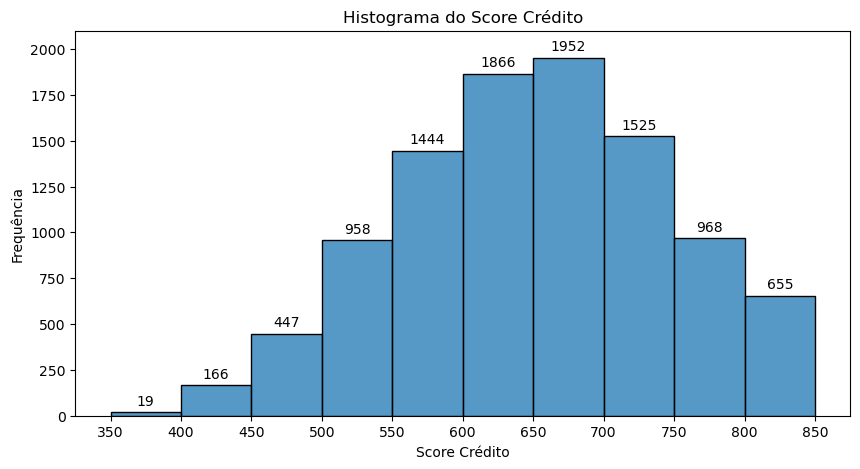

In [17]:
plt.figure(figsize=(10, 5))
hist_Scrore_Credito = sns.histplot(dados.Score_Credito, stat="count", bins=10)
hist_Scrore_Credito.set(xlabel = "Score Crédito", ylabel = "Frequência")
hist_Scrore_Credito.set_title("Histograma do Score Crédito")
hist_Scrore_Credito.set_ylim(0,2100)

for barra in hist_Scrore_Credito.patches:
    altura = barra.get_height()

    if altura > 0:
        hist_Scrore_Credito.annotate(
            str(int(altura)),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

limites = np.histogram_bin_edges(
    dados["Score_Credito"].dropna(),
    bins=10
)

hist_Scrore_Credito.set_xticks(limites)

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\hist_Scrore_Credito.png', dpi=300, bbox_inches='tight')

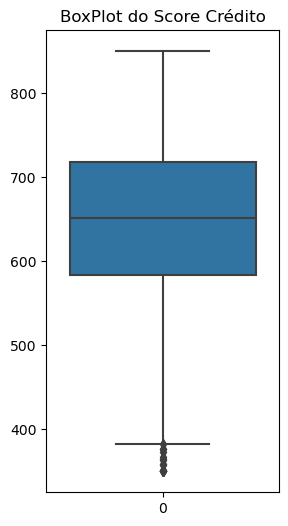

In [18]:
plt.figure(figsize=(3, 6))
boxplot_Score_Credito = sns.boxplot(data=dados.Score_Credito)
boxplot_Score_Credito.set_title("BoxPlot do Score Crédito")

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\boxplot_Scrore_Credito.png', dpi=300, bbox_inches='tight')

In [19]:
tab_freq(dados.Score_Credito, 50, 500)

,Frequência,Porcentagem (%),Acumulada (%)
Score_Credito,,,
<500,632,6.32,6.32
"[500, 550)",958,9.58,15.9
"[550, 600)",1444,14.44,30.34
"[600, 650)",1866,18.66,49.0
"[650, 700)",1952,19.52,68.52
"[700, 750)",1525,15.25,83.77
"[750, 800)",968,9.68,93.45
"[800, 850]",655,6.55,100.0
Total,10000,100.00,


In [20]:
tab_freq(dados.Score_Credito, 50, 500).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Score_Credito.xlsx')

#### Insights

1. 75% dos clientes possuem Score_Credito até 718.
2. Aproximadamente 68% dos clientes possui Score_Credito entre 550 e 750.
3. O Score_Credito é, em média, 650.
4. 6.32% dos clientes abaixo de 500 e 15,90% abaixo de 550.

### Idade

In [21]:
dados['Idade'].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Idade, dtype: float64

In [22]:
medidas_Idade = pd.DataFrame(dados['Idade'].describe())

In [23]:
medidas_Idade.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Idade.xlsx', index=False)

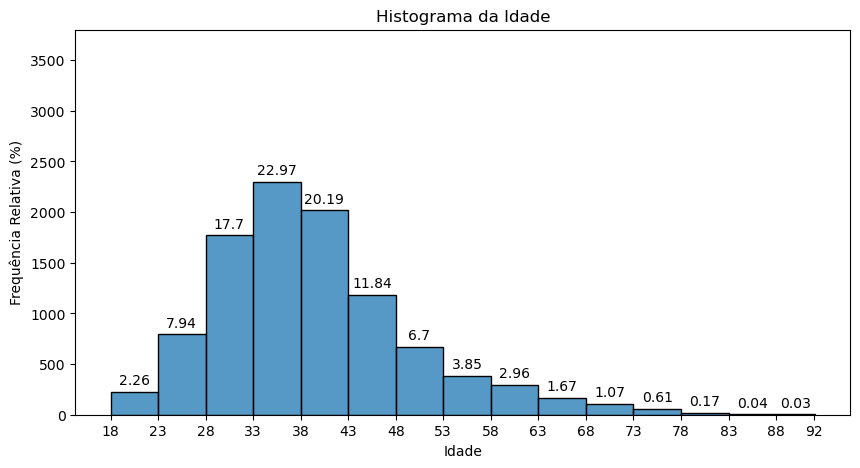

In [24]:
plt.figure(figsize=(10, 5))
hist_Idade = sns.histplot(dados.Idade, stat="count", bins=faixas(dados.Idade, 5))
hist_Idade.set(xlabel = "Idade", ylabel = "Frequência Relativa (%)")
hist_Idade.set_title("Histograma da Idade")
hist_Idade.set_ylim(0,3800)

for barra in hist_Idade.patches:
    altura = barra.get_height()

    if altura > 0:
        hist_Idade.annotate(
            str(int(altura)/100),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

limites = np.histogram_bin_edges(
    dados["Idade"].dropna(),
    bins=faixas(dados.Idade, 5)
).round(0)

hist_Idade.set_xticks(limites)

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\hist_Idade.png', dpi=300, bbox_inches='tight')

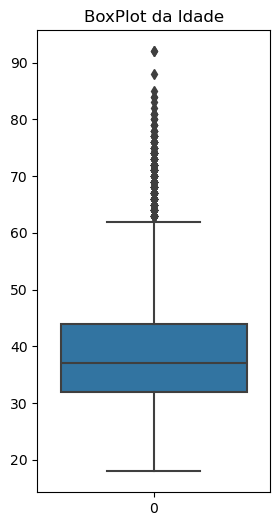

In [25]:
plt.figure(figsize=(3, 6))
boxplot_Idade = sns.boxplot(data=dados.Idade)
boxplot_Idade.set_title("BoxPlot da Idade")

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\boxplot_Idade.png', dpi=300, bbox_inches='tight')

In [110]:
tab_freq(dados.Idade, 5, 25, 55)

,Frequência,Porcentagem (%),Acumulada (%)
Idade,,,
<25,457,4.57,4.57
"[25, 30)",1184,11.84,16.41
"[30, 35)",2038,20.38,36.79
"[35, 40)",2308,23.08,59.87
"[40, 45)",1673,16.73,76.6
"[45, 50)",945,9.45,86.05
"[50, 55)",513,5.13,91.18
≥55,882,8.82,100.0
Total,10000,100.00,


In [112]:
tab_freq(dados.Idade, 10, 25, 55).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Idade.xlsx')

#### Insights

1. 91.18% dos clientes tem até 55 anos de idade.
2. Aproximadamente 72% dos clientes possuem idade entre 25 e 45 anos
3. A média de idade dos cliente é de aproximadamente 39 anos.

### Tempo de cliente

In [28]:
dados['Tempo_Cliente'].describe()

count    10000.000000
mean         5.012800
std          2.892174
min          0.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: Tempo_Cliente, dtype: float64

In [29]:
medidas_Tempo_Cliente = pd.DataFrame(dados['Tempo_Cliente'].describe())
medidas_Tempo_Cliente

,Tempo_Cliente
count,10000.000000
mean,5.012800
std,2.892174
min,0.000000
25%,3.000000
50%,5.000000
75%,7.000000
max,10.000000


In [30]:
medidas_Tempo_Cliente.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Tempo_Cliente.xlsx', index=False)

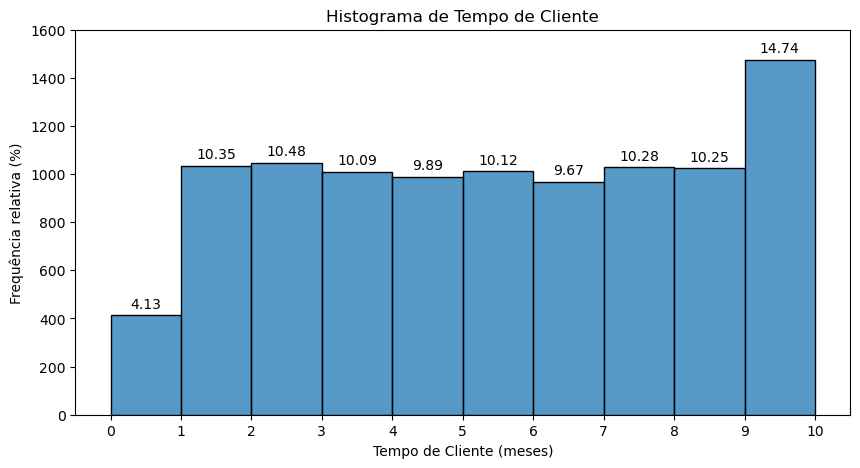

In [115]:
plt.figure(figsize=(10, 5))
hist_Tempo_Cliente = sns.histplot(dados.Tempo_Cliente, stat="count", bins=10)
hist_Tempo_Cliente.set(xlabel = "Tempo de Cliente (meses)", ylabel = "Frequência relativa (%)")
hist_Tempo_Cliente.set_title("Histograma de Tempo de Cliente")
hist_Tempo_Cliente.set_ylim(0,1600)

for barra in hist_Tempo_Cliente.patches:
    altura = barra.get_height()

    if altura > 0:
        hist_Tempo_Cliente.annotate(
            str(int(altura)/100),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

limites = np.histogram_bin_edges(
    dados["Tempo_Cliente"].dropna(),
    bins=10
)

hist_Tempo_Cliente.set_xticks(limites)

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\Tempo_Cliente.png', dpi=300, bbox_inches='tight')

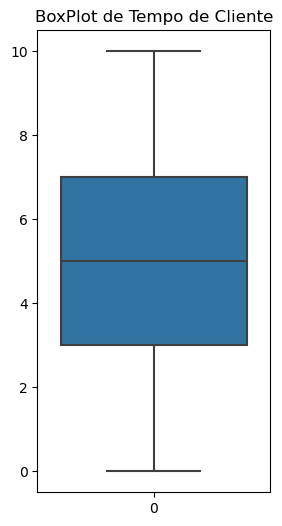

In [32]:
plt.figure(figsize=(3, 6))
boxplot_Tempo_Cliente = sns.boxplot(data=dados.Tempo_Cliente)
boxplot_Tempo_Cliente.set_title("BoxPlot de Tempo de Cliente")

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\Tempo_Cliente.png', dpi=300, bbox_inches='tight')

In [33]:
tab_freq_quali(dados.Tempo_Cliente) ## Verificar essa função para quando o índice for numérico

,Frequência,Porcentagem (%),Acumulada (%)
Tempo_Cliente,,,
2,1048,10.48,10.48
1,1035,10.35,20.83
7,1028,10.28,31.11
8,1025,10.25,41.36
5,1012,10.12,51.48
3,1009,10.09,61.57
4,989,9.89,71.46
9,984,9.84,81.3
6,967,9.67,90.97


In [117]:
pd.Series([10.35, 10.48, 10.09, 9.89, 10.12, 9.67, 10.28, 10.25,9.84]).mean()

10.107777777777777

In [116]:
tab_freq_quali(dados.Tempo_Cliente).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Tempo_Cliente.xlsx')

#### Insights

1. Apenas 4.13% dos clientes possuim 0 meses de tempo de cliente.
2. Clientes com 1 até 9 meses, cada classe dessa corresponde, em média, 10.11% dos clientes.
3. Clientes com 10 meses correspondem  a 4.9% dos clientes.

### Limite de Crédito de Mercado

In [36]:
dados['Limite_Credito_Mercado'].describe()

count    10000.000000
mean       764.858963
std        623.974111
min          0.000000
25%          0.000000
50%        971.985000
75%       1276.440000
max       2508.980000
Name: Limite_Credito_Mercado, dtype: float64

In [37]:
medidas_Limite_Credito_Mercado = pd.DataFrame(dados['Limite_Credito_Mercado'].describe())
medidas_Limite_Credito_Mercado

,Limite_Credito_Mercado
count,10000.000000
mean,764.858963
std,623.974111
min,0.000000
25%,0.000000
50%,971.985000
75%,1276.440000
max,2508.980000


In [38]:
medidas_Limite_Credito_Mercado.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Limite_Credito_Mercado.xlsx')

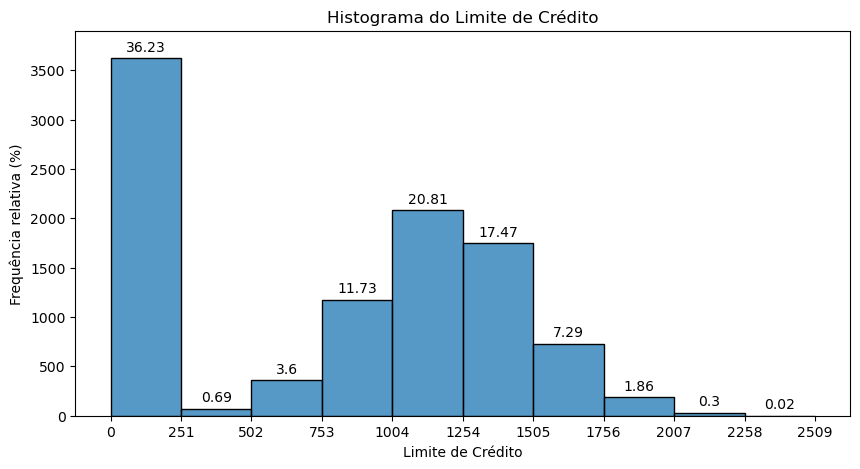

In [125]:
plt.figure(figsize=(10, 5))
hist_Limite_Credito_Mercado = sns.histplot(dados.Limite_Credito_Mercado, stat="count", bins=10)
hist_Limite_Credito_Mercado.set(xlabel = "Limite de Crédito", ylabel = "Frequência relativa (%)")
hist_Limite_Credito_Mercado.set_title("Histograma do Limite de Crédito")
hist_Limite_Credito_Mercado.set_ylim(0,3900)

for barra in hist_Limite_Credito_Mercado.patches:
    altura = barra.get_height()

    if altura > 0:
        hist_Limite_Credito_Mercado.annotate(
            str(int(altura)/100),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

limites = np.histogram_bin_edges(
    dados["Limite_Credito_Mercado"].dropna(),
    bins=10
)

hist_Limite_Credito_Mercado.set_xticks(limites)

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\hist_Limite_Credito_Mercado.png', dpi=300, bbox_inches='tight')

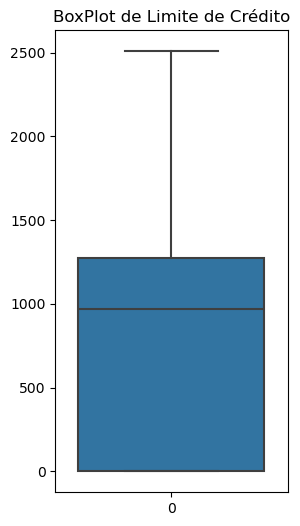

In [40]:
plt.figure(figsize=(3, 6))
boxplot_Limite_Credito_Mercado = sns.boxplot(data=dados.Limite_Credito_Mercado)
boxplot_Limite_Credito_Mercado.set_title("BoxPlot de Limite de Crédito")

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\boxplot_Limite_Credito_Mercado.png', dpi=300, bbox_inches='tight')

In [41]:
tab_freq(dados['Limite_Credito_Mercado'], 250, estouro_superior=1500)

,Frequência,Porcentagem (%),Acumulada (%)
Limite_Credito_Mercado,,,
"[0.0, 250.0)",3623,36.23,36.23
"[250.0, 500.0)",69,0.69,36.92
"[500.0, 750.0)",349,3.49,40.41
"[750.0, 1000.0)",1160,11.60,52.01
"[1000.0, 1250.0)",2068,20.68,72.69
"[1250.0, 1500)",1762,17.62,90.31
≥1500,969,9.69,100.0
Total,10000,100.00,


In [42]:
tab_freq(dados['Limite_Credito_Mercado'], 250, estouro_superior=1500).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Limite_Credito_Mercado.xlsx')

#### Insights

1. 36.23% dos clientes possuem menos que 250 de crédito.
2. 75% dos clientes tem 1276.44 de crédito.
3. Menos de 10% dos clientes possuem 1500 ou mais de crédito.

### Quantidade de Categorias

In [43]:
dados["Qte_Categorias"].describe()

count    10000.000000
mean         1.530200
std          0.581654
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: Qte_Categorias, dtype: float64

In [44]:
medidas_Qte_Categorias = pd.DataFrame(dados["Qte_Categorias"].describe())
medidas_Qte_Categorias

,Qte_Categorias
count,10000.000000
mean,1.530200
std,0.581654
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [45]:
medidas_Qte_Categorias.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Qte_Categorias.xlsx')

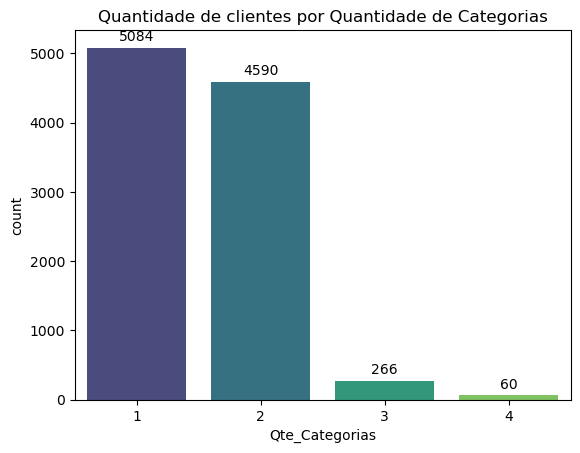

In [46]:
bar_Qte_Categorias = sns.countplot(data=dados, x='Qte_Categorias', palette='viridis')
bar_Qte_Categorias.set_title("Quantidade de clientes por Quantidade de Categorias")

for barra in bar_Qte_Categorias.patches:
    altura = barra.get_height()
    
    if altura > 0:
        bar_Qte_Categorias.annotate(
            str(int(altura)),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\col_Qte_Categorias.png', dpi=300, bbox_inches='tight')

In [47]:
tab_freq_quali(dados["Qte_Categorias"])

,Frequência,Porcentagem (%),Acumulada (%)
Qte_Categorias,,,
1,5084,50.84,50.84
2,4590,45.90,96.74
3,266,2.66,99.4
4,60,0.60,100.0
Total,10000,100.00,


In [48]:
tab_freq_quali(dados["Qte_Categorias"]).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Qte_Categorias.xlsx')

#### Insights

1. 96.74% dos clientes tem estão em até 2 categorias.
2. 50.84% estão somente em uma categoria.
3. Apenas 0.6% dos clientes estão em 4 categorias.

### Soma de pedidos acumulados

In [49]:
dados['Soma_Pedidos_Acumulados'].describe()

count    10000.000000
mean       417.042772
std        239.627055
min          0.050000
25%        212.510000
50%        417.475000
75%        622.455000
max        833.300000
Name: Soma_Pedidos_Acumulados, dtype: float64

In [50]:
medidas_Soma_Pedidos_Acumulados = pd.DataFrame(dados['Soma_Pedidos_Acumulados'].describe())
medidas_Soma_Pedidos_Acumulados

,Soma_Pedidos_Acumulados
count,10000.000000
mean,417.042772
std,239.627055
min,0.050000
25%,212.510000
50%,417.475000
75%,622.455000
max,833.300000


In [51]:
medidas_Soma_Pedidos_Acumulados.to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\medidas_Soma_Pedidos_Acumulados.xlsx')

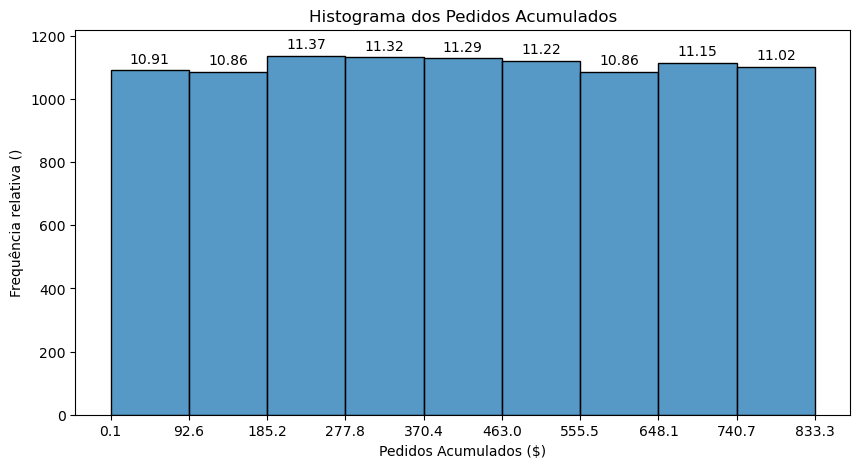

In [131]:
plt.figure(figsize=(10, 5))
hist_Soma_Pedidos_Acumulados = sns.histplot(dados.Soma_Pedidos_Acumulados, stat="count", bins=9)
hist_Soma_Pedidos_Acumulados.set(xlabel = "Pedidos Acumulados ($)", ylabel = "Frequência relativa ()")
hist_Soma_Pedidos_Acumulados.set_title("Histograma dos Pedidos Acumulados")
hist_Soma_Pedidos_Acumulados.set_ylim(0,1220)

for barra in hist_Soma_Pedidos_Acumulados.patches:
    altura = barra.get_height()

    if altura > 0:
        hist_Soma_Pedidos_Acumulados.annotate(
            str(int(altura)/100),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

limites = np.histogram_bin_edges(
    dados["Soma_Pedidos_Acumulados"].dropna(),
    bins=9
)

hist_Soma_Pedidos_Acumulados.set_xticks(limites)

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\hist_Soma_Pedidos_Acumulados.png', dpi=300, bbox_inches='tight')

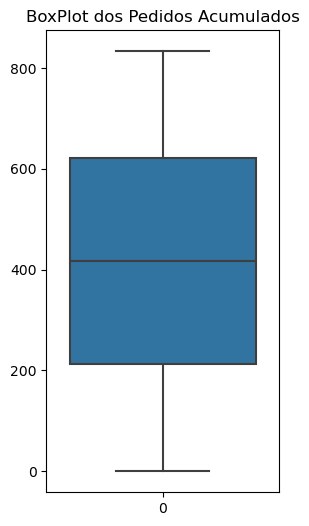

In [53]:
plt.figure(figsize=(3, 6))
boxplot_Soma_Pedidos_Acumulados = sns.boxplot(data=dados.Soma_Pedidos_Acumulados)
boxplot_Soma_Pedidos_Acumulados.set_title("BoxPlot dos Pedidos Acumulados")

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\boxplot_Soma_Pedidos_Acumulados.png', dpi=300, bbox_inches='tight')

In [54]:
tab_freq(dados['Soma_Pedidos_Acumulados'], 100)

,Frequência,Porcentagem (%),Acumulada (%)
Soma_Pedidos_Acumulados,,,
"[0.05, 100.05)",1171,11.71,11.71
"[100.05, 200.05)",1175,11.75,23.46
"[200.05, 300.05)",1219,12.19,35.65
"[300.05, 400.05)",1252,12.52,48.17
"[400.05, 500.05)",1200,12.00,60.17
"[500.05, 600.05)",1220,12.20,72.37
"[600.05, 700.05)",1155,11.55,83.92
"[700.05, 800.05)",1199,11.99,95.91
"[800.05, 833.3]",409,4.09,100.0


In [55]:
tab_freq(dados['Soma_Pedidos_Acumulados'], 100).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Soma_Pedidos_Acumulados.xlsx')

In [56]:
(11.71 + 11.75 + 12.19 + 12.52 + 12 + 12.20 + 11.55 + 11.99 + 4.09)/9

11.11111111111111

#### Insights

1. As oito primeiras faixas, até aproximadamente R$ 800,00, apresentam em média 12% dos clientes.
2. A última faixa representa 4.09% da base.

### Estado

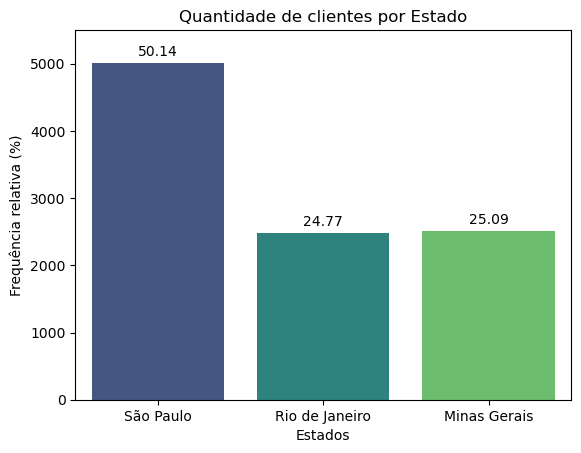

In [136]:
bar_Estado = sns.countplot(data=dados, x='Estado', palette='viridis')
bar_Estado.set_title("Quantidade de clientes por Estado")
bar_Estado.set(xlabel = "Estados", ylabel = "Frequência relativa (%)")
bar_Estado.set_ylim(0,5500)

for barra in bar_Estado.patches:
    altura = barra.get_height()
    
    if altura > 0:
        bar_Estado.annotate(
            str(int(altura)/100),
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.savefig(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\col_Estado.png', dpi=300, bbox_inches='tight')

In [58]:
tab_freq_quali(dados['Estado'])

,Frequência,Porcentagem (%),Acumulada (%)
Estado,,,
São Paulo,5014,50.14,50.14
Minas Gerais,2509,25.09,75.23
Rio de Janeiro,2477,24.77,100.0
Total,10000,100.00,


In [59]:
tab_freq_quali(dados['Estado']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Estado.xlsx')

#### Insights

1. 50.14% dos clientes são de São Paulo.
2. Rio de Janeiro e Minas Gerais, cada um deles, correspondem aproximadamente 25% dos clientes.

### Gênero

In [60]:
tab_freq_quali(dados['Gênero'])

,Frequência,Porcentagem (%),Acumulada (%)
Gênero,,,
Masculino,5457,54.57,54.57
Feminino,4543,45.43,100.0
Total,10000,100.00,


In [61]:
tab_freq_quali(dados['Gênero']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Gênero.xlsx')

#### Insights

1. Os homens correspondem 54.57% dos clientes e as mulheres 45.43%.

### Usa Cartão de Crédito

In [62]:
tab_freq_quali(dados['Usa_Cartao_Credito'])

,Frequência,Porcentagem (%),Acumulada (%)
Usa_Cartao_Credito,,,
1,7055,70.55,70.55
0,2945,29.45,100.0
Total,10000,100.00,


In [63]:
tab_freq_quali(dados['Usa_Cartao_Credito']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Usa_Cartao_Credito.xlsx')

#### Insights

1. 70.55% dos clientes usa cartão de crédito.

### Programa de Fidelidade

In [64]:
tab_freq_quali(dados['Programa_Fidelidade'])

,Frequência,Porcentagem (%),Acumulada (%)
Programa_Fidelidade,,,
1,5151,51.51,51.51
0,4849,48.49,100.0
Total,10000,100.00,


In [65]:
tab_freq_quali(dados['Programa_Fidelidade']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Programa_Fidelidade.xlsx')

#### Insights

1. Aproximadamente metade dos clientes estão no programa de fidelidade.

### Churn

In [66]:
tab_freq_quali(dados['Churn'])

,Frequência,Porcentagem (%),Acumulada (%)
Churn,,,
0,7987,79.87,79.87
1,2013,20.13,100.0
Total,10000,100.00,


In [67]:
tab_freq_quali(dados['Churn']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\freq_Churn.xlsx')

### Intervalo de confiança para a proporção populacional

In [68]:
limite_inf, limite_sup = prop.proportion_confint(
    count=2013, 
    nobs=10000, 
    alpha=(1 - 0.95), 
    method='wilson'
)

In [69]:
print(f"Intervalo de Confiança: [{limite_inf*100:.2f}, {limite_sup*100:.2f}]")

Intervalo de Confiança: [19.36, 20.93]


In [70]:
print('Erro:', 20.13-19.36)

Erro: 0.7699999999999996


#### Insights

1. 20,13% dos clintes são churn.

## Cruzamento de Variáveis (análise bidimensional)

### Cálculo do IV das variáveis com o Churn

importando o woe-iv-bin

In [71]:
from woe_iv_bin import categorical_woe, continuous_woe

#### IV de Score de Crédito com Churn

In [72]:
df_binned, optimized_bins, IV_Score_Credito_Churn = continuous_woe(df=dados, feature='Score_Credito', target='Churn', max_bins=10, min_samples_bin=0.05)

In [73]:
IV_Score_Credito_Churn

,optimized_bin,optimized_WoE,optimized_IV,total_optimized_IV
0,"(350.0, 521.0]",0.115665,0.001388,0.010226
1,"(521.0, 566.0]",0.142428,0.002134,0.010226
2,"(566.0, 598.7000000000003]",-0.020759,0.000042,0.010226
3,"(598.7000000000003, 627.0]",0.091950,0.000896,0.010226
4,"(627.0, 652.0]",0.022682,0.000052,0.010226
5,"(652.0, 678.0]",-0.123937,0.001488,0.010226
6,"(678.0, 704.0]",-0.187507,0.003250,0.010226
7,"(704.0, 735.0]",-0.075441,0.000559,0.010226
8,"(735.0, 778.0]",0.043651,0.000193,0.010226
9,"(778.0, 850.0]",-0.048035,0.000223,0.010226


#### IV de Idade com Churn

In [74]:
df_binned, optimized_bins, IV_Idade_Churn = continuous_woe(df=dados, feature='Idade', target='Churn', max_bins=10, min_samples_bin=0.1)

In [75]:
IV_Idade_Churn

,optimized_bin,optimized_WoE,optimized_IV,total_optimized_IV
0,"(18.0, 29.0]",-1.124924,0.144366,0.746981
1,"(29.0, 33.0]",-1.040152,0.123094,0.746981
2,"(33.0, 36.0]",-0.776223,0.064786,0.746981
3,"(36.0, 39.0]",-0.424263,0.021742,0.746981
4,"(39.0, 43.0]",0.146988,0.003196,0.746981
5,"(43.0, 49.0]",0.948423,0.136878,0.746981
6,"(49.0, 92.0]",1.174627,0.252920,0.746981


#### IV de Tempo de Client e Churn

In [76]:
IV_Tempo_Cliente_Churn = categorical_woe(dados, cat_variable_name='Tempo_Cliente', y_df=dados['Churn'])

In [77]:
IV_Tempo_Cliente_Churn

,WoE,IV,total_IV
feature,,,
0,0.169623,0.001252,0.009075
1,0.125309,0.001688,0.009075
2,-0.072495,0.000539,0.009075
3,0.023776,0.000058,0.009075
4,0.005734,0.000003,0.009075
5,0.013968,0.000020,0.009075
6,-0.004227,0.000002,0.009075
7,-0.198707,0.003823,0.009075
8,-0.089260,0.000796,0.009075


#### IV Limite Crédito de Mercado e Churn

In [78]:
df_binned, optimized_bins, IV_Limite_Credito_Mercado_Churn = continuous_woe(df=dados, feature='Limite_Credito_Mercado', 
                                                                             target='Churn', max_bins=12, min_samples_bin=0.05)

In [79]:
IV_Limite_Credito_Mercado_Churn

,optimized_bin,optimized_WoE,optimized_IV,total_optimized_IV
0,"(0.0, 365.67]",-0.446536,0.063081,0.111587
1,"(365.67, 887.87]",-0.041396,0.000154,0.111587
2,"(887.87, 1034.65]",0.040641,0.000152,0.111587
3,"(1034.65, 1145.4]",0.380784,0.014688,0.111587
4,"(1145.4, 1251.3]",0.435914,0.019526,0.111587
5,"(1251.3, 1364.4400000000005]",0.318475,0.010106,0.111587
6,"(1364.4400000000005, 1513.92]",0.099677,0.000931,0.111587
7,"(1513.92, 2508.98]",0.175462,0.002949,0.111587


#### IV de Quantidade de Categorias com Churn

In [80]:
IV_Qte_Categorias_Churn = categorical_woe(dados, cat_variable_name='Qte_Categorias', y_df=dados['Churn'])

In [81]:
IV_Qte_Categorias_Churn

,WoE,IV,total_IV
feature,,,
1,0.405656,0.093755,0.920732
2,-1.137650,0.411086,0.920732
3,2.851025,0.289848,0.920732
4,4.412942,0.126044,0.920732


#### IV de Soma de pedidos acumulados e Churn

In [82]:
df_binned, optimized_bins, IV_Soma_Pedidos_Acumulados_Churn = continuous_woe(df=dados, feature='Soma_Pedidos_Acumulados', 
                                                                             target='Churn', max_bins=9, min_samples_bin=0.05)

In [83]:
IV_Soma_Pedidos_Acumulados_Churn

,optimized_bin,optimized_WoE,optimized_IV,total_optimized_IV
0,"(0.05, 107.01124999999999]",-0.043445,2.330628e-04,0.002615
1,"(107.01124999999999, 212.51]",-0.013102,2.139188e-05,0.002615
2,"(212.51, 315.4975]",0.031401,1.245064e-04,0.002615
3,"(315.4975, 417.475]",-0.095306,1.104055e-03,0.002615
4,"(417.475, 519.16875]",0.001863,4.346189e-07,0.002615
5,"(519.16875, 622.455]",-0.018121,4.085639e-05,0.002615
6,"(622.455, 729.84875]",0.060434,4.651589e-04,0.002615
7,"(729.84875, 833.3]",0.070005,6.259030e-04,0.002615


#### IV de Estado e Churn

In [84]:
IV_Qte_Genero_Churn = categorical_woe(dados, cat_variable_name='Estado', y_df=dados['Churn'])

In [85]:
IV_Qte_Genero_Churn

,WoE,IV,total_IV
feature,,,
Minas Gerais,0.626250,0.116440,0.166731
Rio de Janeiro,-0.248193,0.014143,0.166731
São Paulo,-0.280334,0.036148,0.166731


#### IV de Gênero e Churn

In [86]:
IV_Qte_Genero_Churn = categorical_woe(dados, cat_variable_name='Gênero', y_df=dados['Churn'])

In [87]:
IV_Qte_Genero_Churn

,WoE,IV,total_IV
feature,,,
Feminino,0.273937,0.036887,0.072964
Masculino,-0.267927,0.036077,0.072964


#### IV de usa cartão de crédito e Churn

In [88]:
IV_Usa_Cartao_Credito_Churn = categorical_woe(dados, cat_variable_name='Usa_Cartao_Credito', y_df=dados['Churn'])

In [89]:
IV_Usa_Cartao_Credito_Churn

,WoE,IV,total_IV
feature,,,
0,0.023422,0.000163,0.000231
1,-0.009877,0.000069,0.000231


#### IV de Programa de Fidelidade e Churn

In [90]:
IV_Programa_Fidelidade_Churn = categorical_woe(dados, cat_variable_name='Programa_Fidelidade', y_df=dados['Churn'])

In [91]:
IV_Programa_Fidelidade_Churn

,WoE,IV,total_IV
feature,,,
0,0.359055,0.069207,0.151624
1,-0.427588,0.082416,0.151624


#### Insights

1. As variáveis que apresentaram IV alto, foram a Idade (0.75) e quantidade de categorais (0.92).
2. As variáveis com poder de separação médio são Limite de Crédito no Mercado (0.11), Estado (0.17) e Programa de Fidelidade (0.15)
3. A variável com poder de separação fraco é Gênero (0.07).
4. As variáveis que apresentaram um poder de separação insignificante foram Score de Crédito (0.01), Tempo de Cliente (0.009), 
Soma de Pedidos Acumulados (0.003), Usa Cartão de Crédito (0.0002)

Conclusão: Vale a pena invesigar as variáveis Idade, Quantidade de Categorias, Limite de Crédito no Mercado, Estado e Programa de Fidelidade.

### Cálculo de frequências

#### Idade x Churn

In [14]:
# Criando faixas etárias
dados['Faixa_Etaria'] = pd.cut(dados['Idade'], bins = faixas(dados['Idade'], 10, 25, 55), labels = labels(dados['Idade'], 10, 25, 55),
                               include_lowest=True, right=False)

In [15]:
freq_Idade_Churn = pd.crosstab(index=dados['Faixa_Etaria'], columns=dados['Churn'], values=dados['ClientId'], aggfunc='count', margins=True)

In [16]:
freq_Idade_Churn

Churn,0,1,All
Faixa_Etaria,,,
<25,417,40,457
"[25, 35)",2975,247,3222
"[35, 45)",3284,697,3981
"[45, 55)",770,688,1458
≥55,541,341,882
All,7987,2013,10000


In [17]:
taxas_quali(dados['Faixa_Etaria'], dados['Churn'], dados['ClientId'])

Churn,0,1,All,Taxa (%)
Faixa_Etaria,,,,
<25,417,40,457,8.75
"[25, 35)",2975,247,3222,7.67
"[35, 45)",3284,697,3981,17.51
"[45, 55)",770,688,1458,47.19
≥55,541,341,882,38.66
All,7987,2013,10000,20.13


In [18]:
taxas_quali(dados['Faixa_Etaria'], dados['Churn'], dados['ClientId']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\taxas_Idade_Churn.xlsx')

##### Insights

1. A faixa etária de 35 a 45 anos corresponde a 39.81% dos clientes e 17.51% deram churn.
2. A faixa etária de 45 a 55 anos apresentou uma taxa de 47.19% de churn, porém essa faixa corresponde a apenas 14.58% dos clientes.
3. Clientes com idades menores que 25 anos apresentam uma taxa de 8.75% de churn, baixa.
4. Clientes com 55 anos ou mais apresentam uma taxa de 38.66% de churn, mas correspondem a apenas 8.82% dos clientes.
5. A base de dados apresenta um total de 20.13% de churn.

#### Quantidade de Categorias e churn

In [7]:
taxas_quali(dados['Qte_Categorias'], dados['Churn'], dados['ClientId'])

Churn,0,1,All,Taxa (%)
Qte_Categorias,,,,
1,3689,1395,5084,27.44
2,4247,343,4590,7.47
3,49,217,266,81.58
4,2,58,60,96.67
All,7987,2013,10000,20.13


In [97]:
freq_Qte_Categorias_Churn = pd.crosstab(index=dados['Qte_Categorias'], columns=dados['Churn'], values=dados['ClientId'], aggfunc='count', margins=True)

In [98]:
freq_Qte_Categorias_Churn

Churn,0,1,All
Qte_Categorias,,,
1,3689,1395,5084
2,4247,343,4590
3,49,217,266
4,2,58,60
All,7987,2013,10000


In [99]:
freq_Qte_Categorias_Churn_percent = pd.crosstab(index=dados['Qte_Categorias'], columns=dados['Churn'], values=dados['ClientId'], aggfunc='count', margins=True, normalize=True)*100

In [100]:
freq_Qte_Categorias_Churn_percent

Churn,0,1,All
Qte_Categorias,,,
1,36.89,13.95,50.84
2,42.47,3.43,45.90
3,0.49,2.17,2.66
4,0.02,0.58,0.60
All,79.87,20.13,100.00


In [101]:
freq_Qte_Categorias_Churn_percent_linhas = pd.crosstab(index=dados['Qte_Categorias'], columns=dados['Churn'], values=dados['ClientId'], aggfunc='count', margins=True, normalize=0)*100

In [102]:
freq_Qte_Categorias_Churn_percent_linhas.round(2)

Churn,0,1
Qte_Categorias,,
1,72.56,27.44
2,92.53,7.47
3,18.42,81.58
4,3.33,96.67
All,79.87,20.13


In [8]:
taxas_quali(dados['Qte_Categorias'], dados['Churn'], dados['ClientId']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\taxas_Qte_Categorias_Churn.xlsx')

##### Insights

1. Pessoas com uma categoria correspondem a 50.84% de dos clientes, dentre eles 27.44% dão churn.
2. Clientes com 2 categorias correspondem a 45.9% dos clientes mas com apenas 7.47% de churn.
3. As outras quantidades de categorias representa apenas 2.75% da base.

#### Limite de Crédito no Mercado e Churn

In [22]:
# Criando faixas de limite de crédito
dados['Faixas_Limite_Credito_Mercado'] = pd.cut(dados['Limite_Credito_Mercado'], 
                                                bins = faixas(dados['Limite_Credito_Mercado'], 250, estouro_superior =1500),
                                                labels = labels(dados['Limite_Credito_Mercado'], 250, estouro_superior =1500),
                                               include_lowest=True, right=False)

In [23]:
taxas_quali(dados['Faixas_Limite_Credito_Mercado'], dados['Churn'], dados['ClientId'])

Churn,0,1,All,Taxa (%)
Faixas_Limite_Credito_Mercado,,,,
"[0.0, 250.0)",3123,500,3623,13.80
"[250.0, 500.0)",48,21,69,30.43
"[500.0, 750.0)",274,75,349,21.49
"[750.0, 1000.0)",938,222,1160,19.14
"[1000.0, 1250.0)",1516,552,2068,26.69
"[1250.0, 1500)",1340,422,1762,23.95
≥1500,748,221,969,22.81
All,7987,2013,10000,20.13


In [24]:
taxas_quali(dados['Faixas_Limite_Credito_Mercado'], dados['Churn'], dados['ClientId']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\taxas_Faixas_Limite_Credito_Mercado_Churn.xlsx')

##### Insights

1. Clientes com até R$ 250,00 de limite de crédito apresentam uma taxa de churn de 13.8% e correspondem a 36.23% da base. 
2. Clientes com limite de crédito entre 250,00 reais e 500,00 reais apresentam uma taxa de churn de 30.43%, porém correspondem a 0.69% da base.
3. A faixa de clientes com limite de crédito entre 1000,00 reais e 1250,00 reais e entre 1250,00 reais e 1550,00 reais possuem taxas de churn iguais a 26.69% e 23.95%, respectivamente.
4. As demais faixas possuem taxas de churn próximas à taxa geral.

#### Estado e Churn

In [105]:
taxas_quali(dados['Estado'], dados['Churn'], dados['ClientId'])

Churn,0,1,All,Taxa (%)
Estado,,,,
Minas Gerais,1705,804,2509,32.04
Rio de Janeiro,2070,407,2477,16.43
São Paulo,4212,802,5014,16.00
All,7987,2013,10000,20.13


In [19]:
taxas_quali(dados['Estado'], dados['Churn'], dados['ClientId']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\taxas_Estado_Churn.xlsx')

##### Insights

1. São Paulo corresponde a 50.14% dos clientes e tem 16% de churn.
2. Minas Gerais corresponde a 25.09% dos clientes e tem 32.04% de churn.
3. Rio de Janeiro corresponde a 24.77% dos clientes e tem 16.43% de churn.

#### Programa de fidelidade X Churn

In [106]:
taxas_quali(dados['Programa_Fidelidade'], dados['Churn'], dados['ClientId'])

Churn,0,1,All,Taxa (%)
Programa_Fidelidade,,,,
0,3563,1286,4849,26.52
1,4424,727,5151,14.11
All,7987,2013,10000,20.13


In [20]:
taxas_quali(dados['Programa_Fidelidade'], dados['Churn'], dados['ClientId']).to_excel(r'C:\Users\Usuario\Documents\Preditiva\Projetos\Churn_App_de_delivery\Graficos e tabelas\taxas_Programa_Fidelidade_Churn.xlsx')

##### Insights

1. Clientes que não estão no programa de fidelidade são 48.49% dos clientes e apresentam uma taxa de 26.52% de churn.
2. Os clientes que estão no programa de fidelidade correspondem a 51.51% e apresentam uma taxa de 14.11% de churn.